## Opgave

De dataset `Live.csv` bevat informatie over verkopers in Azië die via sociale media hun waren aan de man brengen. Jullie moeten proberen om het status_type als label te reproduceren via clusters. Haal de `status_type` kolom dus van je dataset, en hou deze bij om op het einde met jouw gemaakte clusters te vergelijken.

Pas op deze dataset een datareductietechniek toe, en cluster vervolgens de gereduceerde dataset zo goed mogelijk. Zorg voor preprocessing waar nodig, en zoek naar een optimaal model. **Indien je bepaalde keuzes maakt, schrijf kort in de notebook waarom**. Vergelijk op het einde of de labels van je clusteringalgoritme overeenkomen met de originele labels `status_type`, met behulp van een confusion matrix waarbij je de labels meegeeft en de clusters (clusters zijn het resultaat van `fit_predict()`). Trek hier conclusies uit en noteer deze in de notebook.

### Inleveren:
- Hernoem je bestand naar **PE2-VoornaamNaam.ipynb** waarbij je je *eigen naam* invult.
- Laad dit bestand op naar de uploadzone op toets.ap.be voor het einde van deze test.

Jullie krijgen **60 minuten** de tijd.

### Kolommen dataset:

- status_id : id van de post/interactie
- status_type: video, photo, link, status, ... dit is het label dat we gaan proberen te voorspellen via clustering.
- status_published: tijdstip
- num_reactions : aantal reacties
- num_comments : aantal commentaren
- num_shares : aantal keer gedeeld
- num_likes : aantal likes
- num_loves : aantal keer 'hartje' emoji
- num_wows : gelijkaardig als hierboven
- num_hahas : gelijkaardig als hierboven
- num_sads : gelijkaardig als hierboven
- num_angrys : gelijkaardig als hierboven

### Indicatieve puntenverdeling /20
- goede algoritmes: 2 keer 4 ptn
- goede beschrijving over keuze van deze algoritmes: 4 ptn
- overige noodzakelijke stappen: 8 ptn
- Hierna wordt er gekeken naar code stijl

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, confusion_matrix, ConfusionMatrixDisplay

In [48]:
data = pd.read_csv("Live.xls")
data.shape

(7050, 16)

In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   object 
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(9), object(3)
memory 

In [50]:
print(data.isna().sum()) #welke waarden er ontbereken in komeme,
print(data.duplicated().sum()) #aantal duplicaten
data['status_type'].nunique() #er zijn 4 soorten


status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64
51


4

In [51]:
#de deze 'columms' kolommen bevatten geen waarde dus de laat ik weg vallen
#deze kols zijn ook niet relevant voor deze opdracht en hebben een omzetten nog die niet mogelijke is omdat data later in preprossing fase zal gaan.
data = data.drop(columns=['Column1', 'Column3', 'Column2', 'Column4', 'status_id', 'status_published'])

y = data["status_type"]
X = data.drop(columns=["status_type"])

print(f"Originel shape na weglaten van de onnodige data: {X.shape}")
y.nunique()

Originel shape na weglaten van de onnodige data: (7050, 9)


4

In [54]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [81]:
pca = PCA(0.95)
X_pca = pca.fit_transform(X_scaled)

n_components = X_pca.shape[1]

gereduceerd = (1-n_components/X.shape[1]) * 100

print(f"features: {X.shape}")
print(f"features na reductie: {X_pca.shape}")
print(f"Data reductie: {gereduceerd:.1f}%")

features: (7050, 9)
features na reductie: (7050, 7)
Data reductie: 22.2%


In [86]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_pca)
sil = silhouette_score(X_pca, kmeans.labels_)*100
print(f"{sil:.2f}")

76.09


In [80]:
dbscan_params = [(0.3, 5), (0.3, 10), (0.5, 5), (0.5, 10),
                 (0.7, 5), (0.7, 10), (1.0, 5), (1.0, 10)]

best_sil = -1
best_param = None

for eps, sample in dbscan_params:
    dbscan = DBSCAN(eps=eps, min_samples=sample).fit(X_pca)
    
    if len(set(dbscan.labels_)) >= 2:
        sil = silhouette_score(X_pca, dbscan.labels_)
        
        if sil > best_sil:
            best_sil = sil
            best_param = (eps, sample)
        
silhouette_post = best_sil
        
        
print(f"{silhouette_post}")
print(f"{best_param}")

0.52275715260818
(1.0, 10)


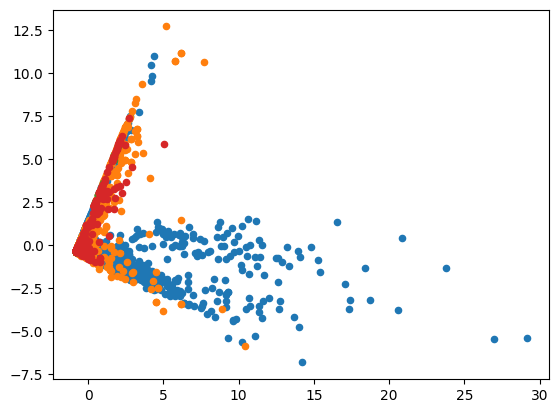

In [90]:
pca_x_2 = PCA(n_components=2)
X_2 = pca.fit_transform(X_scaled)

for label in data["status_type"].unique():
    mask =  data["status_type"] == label

    plt.scatter(X_2[mask, 0], X_2[mask, 1], s=20, label=label)
